# Clinical Research Compliance Assistant
### An expert agent on ICH GCP, expedited safety reporting and the Declaration of Helsinki — Gemini + ChromaDB + LangGraph

**Author:** David Naranjo Ramírez · Master in Data Science & AI, Evolve Academy · Generative AI module, final project

**Domain.** Clinical-trial compliance questions are answered from three authoritative texts: **ICH E6(R3)** *Good Clinical Practice* (2025), **ICH E2A** *Clinical Safety Data Management: definitions and standards for expedited reporting* and the **WMA Declaration of Helsinki** (2024). The domain is not arbitrary: I spent five years supporting clinical-trial software (Medidata Rave, Pfizer and Novo Nordisk platforms) and hold the ICH GCP E6(R2) certification, so I can judge whether an answer is right — which is what an expert assistant needs from its author.

**What the notebook shows** (one section per rubric item):

| # | Section | Rubric |
|---|---|---|
| 1 | Setup (local / Colab, API key hygiene) | Requirements |
| 2 | Knowledge base: sources, pre-processing, chunking | Base de conocimiento |
| 3 | Gemini embeddings + ChromaDB, idempotent build | Base de conocimiento |
| 4 | Retrieval sanity check **before** the agent (EN/ES, out-of-domain, calibrated threshold) | RAG |
| 5 | System prompt v4 and why (v1 vs v4 on the same question) | Ingeniería de prompts |
| 6 | The LangGraph agent and its trace | Agente LangGraph |
| 7 | Conversation memory: referential follow-ups, thread isolation | Memoria |
| 8 | Documented example conversations | ≥ 5 ejemplos |
| 9 | Evaluation: reviewed bilingual golden set, LLM judge, held-out set | Calidad |
| 10 | Interactive chat cell | Celda de chat |
| 11 | Limitations and next steps | Documentación |

**How to run.** Locally: `uv sync --extra dev`, put `GEMINI_API_KEY=...` in `.env`, then `uv run jupyter lab notebooks/`. On Google Colab: run the setup cell below (it clones the repo and installs it) and add `GEMINI_API_KEY` to Colab *Secrets*. The embedding cache is committed, so the knowledge base is rebuilt locally in seconds **without** calling the embeddings API; only the chat questions call Gemini.

## 1 · Setup

The API key is read from the environment (`.env` locally, *Secrets* on Colab) and never written in code. The cell prints its length as the only sanity check. An optional `GEMINI_API_KEY_BACKUP` from a second Google Cloud project is a second daily quota: if a `[llm] daily quota hit; switching to backup key` line appears in an output below, that is the failover in `agent.py` doing its job, not an error.

In [1]:
import os, sys, subprocess, logging, time, json
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO = "https://github.com/dnarram/clinical-research-compliance-assistant.git"
    if not Path("clinical-research-compliance-assistant").exists():
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "clinical-research-compliance-assistant"], check=True)
    sys.path.insert(0, "clinical-research-compliance-assistant/src")
    from google.colab import userdata  # type: ignore
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")

from compliance_assistant.config import load_settings, load_api_keys, PROJECT_ROOT

settings = load_settings()
api_keys = load_api_keys()   # primary + optional GEMINI_API_KEY_BACKUP (fails over on a daily quota)

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)

class _OnlyAgentLogs(logging.Filter):
    # Keep the agent's [node] lines; drop HTTP client chatter (httpx, google-genai, chromadb).
    def filter(self, record):
        return record.name.startswith("compliance_assistant") or record.levelno >= logging.WARNING

for handler in logging.getLogger().handlers:
    handler.addFilter(_OnlyAgentLogs())
import warnings; warnings.filterwarnings("ignore")

from importlib.metadata import version as _v
print(f"project root : {PROJECT_ROOT}")
print(f"LLM          : {settings.llm_model}   embeddings: {settings.embedding_model} (dim {settings.embedding_dim})")
print(f"chunking     : {settings.chunk_size}/{settings.chunk_overlap}   retrieval: k={settings.k}, fetch_k={settings.fetch_k}, MMR λ={settings.mmr_lambda}")
print(f"API keys     : {len(api_keys)} loaded ({', '.join(str(len(k)) + ' chars' for k in api_keys)})")
print("versions     : " + ", ".join(f"{p} {_v(p)}" for p in ("langgraph", "langchain-core", "langchain-google-genai", "langchain-chroma", "chromadb")))

project root : /Users/davidnaranjoramirez/proyectos/Asistente-Experto-con-Gemini- RAG-y-Agentes
LLM          : gemini-3.5-flash-lite   embeddings: gemini-embedding-2 (dim 768)
chunking     : 500/50   retrieval: k=6, fetch_k=24, MMR λ=0.6
API keys     : 2 loaded (53 chars, 53 chars)
versions     : langgraph 1.2.20, langchain-core 1.7.6, langchain-google-genai 4.4.3, langchain-chroma 1.1.0, chromadb 1.5.9


## 2 · Knowledge base

Three public documents, listed in `data/kb/sources.yaml` with their URL and SHA-256. They are **not redistributed** in the repository (ICH and WMA texts are quoted with attribution — see `docs/sources.md`); the cell below downloads them with `scripts/00_download_sources.py` if `data/kb/raw/` is empty, verifying the hashes. If you only want to *use* the assistant you can skip this: the embedding cache is committed.

In [2]:
from compliance_assistant.ingestion import load_sources

sources = load_sources(settings)
missing = [s for s in sources if not s.pdf_path(settings).exists()]
if missing:
    print(f"Fetching {len(missing)} source file(s) from their publishers…")
    result = subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "00_download_sources.py")], check=False)
    if result.returncode != 0:
        print("WARNING: a publisher's file no longer matches the recorded sha256 (see output above). "
              "The pre-processing demo below uses whatever was downloaded; the knowledge base itself comes "
              "from the committed embedding cache and is unaffected.")

print(f"{'doc_id':<20} {'format':<6} {'pages':<8} title")
for s in sources:
    pages = f"{s.pages[0]}-{s.pages[1]}" if s.pages else "all"
    print(f"{s.doc_id:<20} {s.format:<6} {pages:<8} {s.title[:80]}")

doc_id               format pages    title
ich_e2a              pdf    3-12     ICH E2A — Clinical Safety Data Management: Definitions and Standards for Expedit
ich_e6_r3            pdf    8-86     ICH E6(R3) — Guideline for Good Clinical Practice (Step 4, 6 January 2025)
wma_helsinki_2024    html   all      WMA Declaration of Helsinki — Ethical Principles for Medical Research Involving 


### 2.1 · Pre-processing: what the raw text looks like and what we keep

The ICH PDFs carry a running header ("ICH E6(R3) Guideline") and a page number on every page, hyphenate words across lines and start with a table of contents. `ingestion.clean_text` removes lines that repeat on ≥ 50 % of pages, page-number-only lines and dotted TOC leaders, and re-joins hyphenated words. The Declaration of Helsinki is indexed from the WMA web page because the PDF export loses the paragraph numbers and corrupts ligatures. Every chunk then carries `doc_id`, `section` (ICH "2.8.10", Helsinki "¶28") and `page`, which is what makes citations possible.

In [3]:
from compliance_assistant.ingestion import load_pdf, clean_pages, find_repeated_lines, ingest

e6 = next(s for s in sources if s.doc_id == "ich_e6_r3")
if not e6.pdf_path(settings).exists():
    raise RuntimeError("ICH E6(R3) PDF not available offline — run scripts/00_download_sources.py (network) to see this demo; "
                       "sections 3 onwards work from the committed cache without it.")
raw_pages = load_pdf(e6.pdf_path(settings), e6.doc_id, pages=(22, 22))
clean = clean_pages(load_pdf(e6.pdf_path(settings), e6.doc_id, pages=e6.pages))
repeated = find_repeated_lines(load_pdf(e6.pdf_path(settings), e6.doc_id, pages=e6.pages))

print("Lines detected as running header/footer:", sorted(repeated))
print("\n--- RAW page 22 (first 400 chars) ---")
print(raw_pages[0].text[:400])
print("\n--- CLEAN page 22 (first 400 chars) ---")
print(next(p for p in clean if p.page == 22).text[:400])

Lines detected as running header/footer: ['#', 'ich e#(r#) guideline']

--- RAW page 22 (first 400 chars) ---
ICH E6(R3) Guideline 
 
15 
 
Unfavourable medical events occurring in participants before investigational 
product administration (e.g., during screening) should be considered and 
reported to the sponsor if required by the protocol. 
 
(b) All serious adverse events (SAEs) should be reported immediately  (after the 
investigator reasonably becomes aware of the event)  to the sponsor . The 
inves

--- CLEAN page 22 (first 400 chars) ---
Unfavourable medical events occurring in participants before investigational
product administration (e.g., during screening) should be considered and
reported to the sponsor if required by the protocol.

(b) All serious adverse events (SAEs) should be reported immediately (after the
investigator reasonably becomes aware of the event) to the sponsor . The
investigator should also include an assessm


ich_e2a                68 chunks     67 with a section label   mean 358 chars
ich_e6_r3             665 chunks    665 with a section label   mean 289 chars
wma_helsinki_2024      68 chunks     65 with a section label   mean 298 chars
TOTAL                 801 chunks

Example chunk: ich_e6_r3:p24:c6:ddc3a243
{
  "doc_id": "ich_e6_r3",
  "title": "ICH E6(R3) \u2014 Guideline for Good Clinical Practice (Step 4, 6 January 2025)",
  "short_cite": "ICH E6(R3)",
  "page": 24,
  "section": "2.8.10",
  "chunk_index": 6,
  "url": "https://database.ich.org/sites/default/files/ICH_E6%28R3%29_Step4_FinalGuideline_2025_0106.pdf"
}
2.8.10 The informed consent discussion and the informed consent materials to be provided
to participants should explain the following as applicable:

(a) The purpose of the trial;

(b) That the trial involves research and summary of the experimental aspects of
the trial;

(c) The trial ’s investigat …


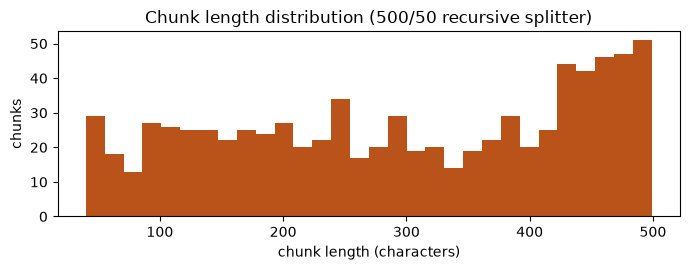

In [4]:
import matplotlib.pyplot as plt

all_chunks = {s.doc_id: ingest(s, settings) for s in sources if s.pdf_path(settings).exists()}
for doc_id, chunks in all_chunks.items():
    with_section = sum(1 for c in chunks if c.metadata["section"])
    print(f"{doc_id:<20} {len(chunks):>4} chunks   {with_section:>4} with a section label   "
          f"mean {sum(len(c.text) for c in chunks)//len(chunks)} chars")
print(f"{'TOTAL':<20} {sum(len(c) for c in all_chunks.values()):>4} chunks")

example = next(c for c in all_chunks["ich_e6_r3"] if c.metadata["section"] == "2.8.10")
print("\nExample chunk:", example.id)
print(json.dumps(example.metadata, indent=2))
print(example.text[:300], "…")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist([len(c.text) for chunks in all_chunks.values() for c in chunks], bins=30, color="#B95319")  # DNR copper (docs/brand_application.md)
ax.set_xlabel("chunk length (characters)"); ax.set_ylabel("chunks"); ax.set_title("Chunk length distribution (500/50 recursive splitter)")
plt.tight_layout(); plt.show()

## 3 · Gemini embeddings + ChromaDB (idempotent build)

Design decision: the **versioned embedding cache** (`data/kb/embeddings/*.jsonl.gz`) is the source of truth, not the Chroma directory. `manifest.json` records the file hash, embedding model, dimension and chunking per document, so a document is only re-embedded when one of those changes. Chroma is rebuilt from the cache with Chroma's native `add(embeddings=…)` — **zero API calls** — which is also how the Streamlit app and this notebook get their collection on a fresh machine.

Documents are embedded with `task_type=RETRIEVAL_DOCUMENT` and queries with `RETRIEVAL_QUERY` (asymmetric retrieval). `--dry-run` first: count the chunks and compare with the free-tier quota before spending it.

In [5]:
from compliance_assistant.vectorstore import (TASK_DOCUMENT, build_kb, build_or_load, get_embeddings,
                                              get_query_embeddings, load_manifest)

dry = build_kb(settings, None, dry_run=True)
batches = -(-dry.total_chunks // settings.embedding_batch_size)
print(f"dry run: {dry.chunks_per_doc} -> {dry.total_chunks} chunks = {batches} embedding requests (free tier ≈ 1000/day)")

doc_embedder = get_embeddings(settings, api_keys, TASK_DOCUMENT)
report = build_kb(settings, doc_embedder)          # embeds only what the cache lacks
print(f"\nembedded now: {report.total_embedded} new chunks  (0 = everything was cached)")

query_embedder = get_query_embeddings(settings, api_keys)   # RETRIEVAL_QUERY + on-disk cache of query vectors
vectorstore = build_or_load(settings, query_embedder)
print(f"Chroma collection '{settings.collection_name}': {vectorstore._collection.count()} chunks, cosine space")
print("\nmanifest.json:")
for doc_id, entry in load_manifest(settings).items():
    print(f"  {doc_id:<20} n_chunks={entry['n_chunks']:<4} model={entry['embedding_model']} dim={entry['embedding_dim']} "
          f"chunking={entry['chunk_size']}/{entry['chunk_overlap']} built={entry['built_at'][:10]}")

dry run: {'ich_e2a': 68, 'ich_e6_r3': 665, 'wma_helsinki_2024': 68} -> 801 chunks = 17 embedding requests (free tier ≈ 1000/day)


[embed] ich_e2a: 0 new chunks (68 cached)


[embed] ich_e6_r3: 0 new chunks (665 cached)


[embed] wma_helsinki_2024: 0 new chunks (68 cached)


[chroma] loaded clinical_compliance from /Users/davidnaranjoramirez/proyectos/Asistente-Experto-con-Gemini- RAG-y-Agentes/data/chroma



embedded now: 0 new chunks  (0 = everything was cached)
Chroma collection 'clinical_compliance': 801 chunks, cosine space

manifest.json:
  ich_e2a              n_chunks=68   model=gemini-embedding-2 dim=768 chunking=500/50 built=2026-11-08
  ich_e6_r3            n_chunks=665  model=gemini-embedding-2 dim=768 chunking=500/50 built=2026-11-08
  wma_helsinki_2024    n_chunks=68   model=gemini-embedding-2 dim=768 chunking=500/50 built=2026-11-08


## 4 · Retrieval sanity check — before connecting the agent

The brief asks to verify the collection answers test queries *before* wiring the LLM. Three things to check:

1. **Precision** — does the top-3 point at the right section?
2. **Cross-lingual retrieval** — the corpus is English, users ask in Spanish too. The same question in both languages should hit the same passages (`gemini-embedding-2` is multilingual; the agent additionally rewrites every non-English question into English before searching).
3. **Out-of-domain** — a compliance assistant must *refuse* questions it cannot ground. Gemini cosine scores live in a narrow band, so the refusal threshold is **calibrated**, not guessed: `scripts/02_sanity_retrieval.py --calibrate` records the max score of in-domain and out-of-domain queries and stores the midpoint of the gap in `data/kb/calibration.json`.

In [6]:
from compliance_assistant.retrieval import scored_search, cite

def show(query, k=3):
    hits = scored_search(vectorstore, query, k)
    print(f"\n▶ {query}")
    for doc, score in hits:
        print(f"   {score:.3f}  {cite(doc.metadata):<34} {doc.page_content[:90].replace(chr(10), ' ')}…")
    return max(s for _, s in hits)

show("What is the timeline for expedited reporting of fatal or life-threatening unexpected ADRs?")
show("¿Cuál es el plazo de notificación expeditiva de una reacción adversa inesperada mortal o potencialmente mortal?")
show("What does the Declaration of Helsinki say about participants who cannot give consent?")
show("Which GLP-1 drug is best for weight loss?")          # out of domain: clinical advice
_ = show("¿Cuál es la mejor receta de paella valenciana?")   # out of domain: unrelated


▶ What is the timeline for expedited reporting of fatal or life-threatening unexpected ADRs?
   0.878  ICH E2A §1, p.7                    1. Fatal or Life-Threatening Unexpected ADRs Certain ADRs may be sufficiently alar ming so…
   0.854  ICH E2A §2, p.7                    2. All Other Serious, Unexpected ADRs Serious, unexpected reactions (ADRs) that are not fa…
   0.854  ICH E2A §1, p.7                    unexpected ADRs occurring in clinical investigations qualify for very rapid reporting. Reg…

▶ ¿Cuál es el plazo de notificación expeditiva de una reacción adversa inesperada mortal o potencialmente mortal?
   0.821  ICH E2A §1, p.7                    1. Fatal or Life-Threatening Unexpected ADRs Certain ADRs may be sufficiently alar ming so…
   0.811  ICH E2A §1, p.7                    unexpected ADRs occurring in clinical investigations qualify for very rapid reporting. Reg…
   0.801  ICH E2A §2, p.7                    2. All Other Serious, Unexpected ADRs Serious, unexpected rea

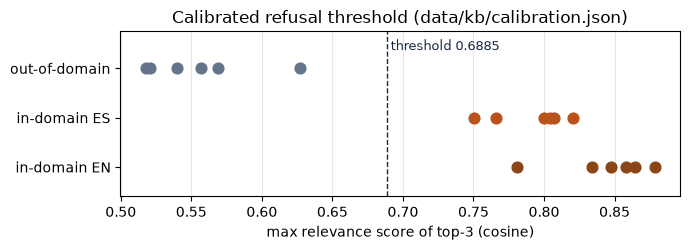

in-domain EN min 0.781 · ES min 0.750 · OOD max 0.627 · threshold 0.6885


In [7]:
calibration = json.loads(settings.calibration_path.read_text(encoding="utf-8"))
threshold = settings.resolved_threshold()
en, es, ood = calibration["in_domain_max_scores"]["en"], calibration["in_domain_max_scores"]["es"], calibration["out_of_domain_max_scores"]

fig, ax = plt.subplots(figsize=(7, 2.6))
# DNR palette: in-domain in the copper ramp (dark -> mid), out-of-domain in slate, gate in navy.
for y, (label, xs, color) in enumerate([("in-domain EN", en, "#8C4516"), ("in-domain ES", es, "#B95319"), ("out-of-domain", ood, "#64748B")]):
    ax.scatter(xs, [y]*len(xs), s=60, color=color, label=label, zorder=3)
ax.axvline(threshold, color="#162B43", ls="--", lw=1)
ax.set_ylim(-0.6, 2.75)
ax.text(threshold, 2.45, f" threshold {threshold}", va="center", fontsize=9, color="#162B43")
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["in-domain EN", "in-domain ES", "out-of-domain"]); ax.set_xlabel("max relevance score of top-3 (cosine)")
ax.set_title("Calibrated refusal threshold (data/kb/calibration.json)"); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()
print(f"in-domain EN min {min(en):.3f} · ES min {min(es):.3f} · OOD max {max(ood):.3f} · threshold {threshold}")

### 4.1 · Context expansion: why a 500-character chunk is not enough

The first full golden-set run showed answers built on half a list: ICH E2A's definition of *serious* came back with two of its five criteria, because the definition straddles two chunks. Retrieval now widens every chunk to its whole section when the section is short (≤ 4,000 characters: a numbered requirement, a Helsinki paragraph, the 22 consent elements of E6(R3) §2.8.10) and to its neighbouring chunks otherwise. The neighbours come from the collection itself — no API calls. Below: the chunk retrieval picks, and the passage the model actually reads.

In [8]:
from compliance_assistant.retrieval import ContextIndex, expand, to_sources

index = ContextIndex.from_store(vectorstore, settings.section_budget_chars)
# The question names E2A, so document routing restricts the search to it (metadata filter).
hit, score = vectorstore.similarity_search_with_relevance_scores(
    "How does ICH E2A define a serious adverse event?", k=1, filter={"doc_id": "ich_e2a"})[0]
passage = to_sources(*expand([hit], [score], index))[0]
print(f"retrieved chunk ({len(hit.page_content)} chars) — {cite(hit.metadata)}\n{hit.page_content}\n")
print(f"passage sent to the model ({len(passage.text)} chars) — {passage.citation}\n{passage.text}")

retrieved chunk (484 chars) — ICH E2A §3, p.5
After reviewing the various regulatory and other definitions in use or under
discussion elsewhere, the following definition is believed to encompass the spirit
and meaning of them all:
A serious adverse event (experience) or reaction is any untoward medical
occurrence that at any dose:
* results in death,
* is life-threatening,
NOTE: The term "life-threatening" in the definition of "serious" refers to an
event in which the patient was at risk of death at the time of the event; it

passage sent to the model (1371 chars) — ICH E2A §3, p.5
specific event (as in mild, moderate, or severe myocardial infarction); the
event itself, however, may be of rela tively minor medical significance (such
as severe headache). This is not the same as "serious," which is based on
patient/event outcome or action criteria usually associated with events that
pose a threat to a patient's life or fun ctioning. Seriousness (not severity)
serves as a guide for defini

## 5 · System prompt — design and justification

The prompt went through four versions (`src/compliance_assistant/prompts.py`, history in `docs/prompt_iterations.md`). **v4** is in use. Its clauses and why each one exists:

| Clause | Why |
|---|---|
| Role + audience (CRAs, coordinators, data managers, PV staff) + explicit list of the three documents | Sets register and lets the model say what it *does not* cover |
| **Grounding**: answer only from the numbered passages; cite every factual sentence as `[n]` | Traceability is the point of RAG in a regulated setting; the numbers map to the sources panel |
| **Insufficiency, graded**: answer the part the passages cover and say which part they do not; only when nothing is relevant say it is not in the knowledge base (in the user's language) and list what it covers; never invent section numbers or timelines | The rubric asks how the agent behaves without information. v3 refused a whole multi-step question (investigator → sponsor → regulator) although every step was in the passages |
| **Multi-step answers**: combine several passages step by step, citing each step | Reporting chains span E6(R3) and E2A |
| **Complete lists**: give every item the passages contain, or say the list continues | v3 presented 4 of 22 consent elements as if complete |
| **Sources that differ**: attribute each position to its document instead of merging | E6(R3) and Helsinki overlap (consent, vulnerable participants) but are not identical |
| **Language policy**: answer in the user's language, quote regulatory wording verbatim in English, keep SAE/SUSAR/IB/IMP untranslated | Corpus is English, users are Spanish-speaking; verbatim quotes keep legal precision |
| **Scope and tone**: regulatory information, not legal/medical advice; redirect off-topic requests | Liability and focus |
| **Format**: direct answer first, then detail, no closing summary | Shorter, scannable answers in a chat UI |

The LLM also gets a deterministic `Reply in English.` / `Responde en español.` line in the user message: during testing the system-prompt rule alone was not enough (an English question once came back in Spanish).

In [9]:
from compliance_assistant.prompts import SYSTEM_PROMPTS
print(SYSTEM_PROMPTS["v4"])

You are a regulatory compliance assistant for clinical research. Your users are clinical
research associates, study coordinators, data managers and pharmacovigilance staff. Your
knowledge base contains: ICH E6(R3) Good Clinical Practice, ICH E2A (definitions and
standards for expedited safety reporting) and the WMA Declaration of Helsinki (2024).

GROUNDING
- Answer only from the numbered context passages. Do not use outside knowledge, even if
  you believe you know the answer.
- Cite the passage that supports each statement with its number in square brackets,
  e.g. "within 7 calendar days [2]". Every factual sentence needs at least one citation.
- A question may need several passages combined (for example a reporting chain:
  investigator to sponsor, then sponsor to regulators with its timelines). Build the
  answer step by step from the passages, citing each step.
- If the passages answer only part of the question, answer that part and say clearly
  which part they do not cover. Onl

**v1 vs v4 on the same question.** v1 is the bare "answer from the documents" prompt from the class notebook. Compare attribution and structure.

In [10]:
from compliance_assistant.agent import Assistant, make_llm

llm = make_llm(settings, api_keys)
question = "Who is responsible for reporting a SUSAR to the regulatory authorities, and how fast?"
for version in ("v1", "v4"):
    assistant_v = Assistant(llm, vectorstore, load_settings(prompt_version=version))
    answer = assistant_v.ask(question)
    print(f"\n==================== prompt {version} ====================")
    print(answer.text)
    print("sources:", "; ".join(f"[{s.n}] {s.citation}" for s in answer.sources))
    time.sleep(2)

[rewrite_query] first turn, English: used as-is


[retrieve] max_score=0.815 threshold=0.689 grounded=True chunks=6 passages=5 routed=-


[llm] daily quota hit; switching to backup key #2


[generate] 651 chars, 5 sources



==================== prompt v1 ====================
Based on the provided documents:

* **Who is responsible:** The **sponsor** is responsible for expediting the reporting of all suspected, unexpected and serious adverse reactions (SUSARs) to the regulatory authorities.
* **How fast:** 
  * For **fatal or life-threatening unexpected ADRs**, regulatory agencies must be notified as soon as possible, but **no later than 7 calendar days** after the sponsor first has knowledge that a case qualifies, followed by as complete a report as possible within **8 additional calendar days**.
  * For other SUSARs, reporting should be undertaken in accordance with applicable regulatory requirements and ICH E2A.
sources: [1] ICH E6(R3) §3.13.2, p.43; [2] ICH E2A §1, p.7; [3] ICH E2A §1, p.9; [4] ICH E2A §3, pp.8–9; [5] ICH E6(R3) §A.1.2, p.59


[rewrite_query] first turn, English: used as-is


[retrieve] max_score=0.815 threshold=0.689 grounded=True chunks=6 passages=5 routed=-


[generate] 1802 chars, 5 sources



==================== prompt v4 ====================
The sponsor is responsible for expediting the reporting of SUSARs to regulatory authorities [1], with fatal or life-threatening unexpected ADRs requiring very rapid notification "as soon as possible but no later than 7 calendar days after first knowledge by the sponsor that a case qualifies, followed by as complete a report as possible within 8 additional calendar days" [2]. 

The detailed responsibilities and timelines include:
- The sponsor should expedite reporting to regulatory authorities "of all suspected, unexpected and serious adverse reactions (i.e., SUSARs)" in accordance with applicable regulatory requirements and ICH E2A [1].
- Safety reporting must be undertaken by assessing the expectedness of the reaction using reference safety information (RSI) in the IB or alternative documents [1].
- For fatal or life-threatening unexpected ADRs, regulatory agencies should be notified "as soon as possible but no later than 7 calenda

## 6 · The LangGraph agent

An explicit `StateGraph` rather than a tool-calling agent: the brief requires the knowledge base to be used on **every** query, the free tier makes extra LLM calls expensive, and a fixed topology is easy to trace.

```
START → rewrite_query → retrieve → (route) → generate → END
                                           ↘ refuse  → END
```

* **rewrite_query** — turns the latest message into a *standalone English question* using the windowed history (resolves "that situation", "the same rule"; translates Spanish). Skips the LLM call on a first English turn.
* **retrieve** — scores the top-k over the whole collection (`similarity_search_with_relevance_scores`) and gates on the calibrated threshold; if the question **names documents** ("E6(R3)", "Helsinki", "E2A" — aliases in `sources.yaml`) the top-k is shared between them with a metadata filter, otherwise plain **MMR** (`k=6, fetch_k=24, λ=0.6`); finally each chunk is **expanded** to its section (4.1).
* **route** — `Literal["generate", "refuse"]` on `grounded`.
* **generate** — system prompt v4 + windowed history + numbered passages + question (+ language line).
* **refuse** — templated answer in the user's language, no LLM call.

State keeps `context`/`sources` *outside* `messages`, so the persisted conversation stays small and the memory window counts turns, not passages.

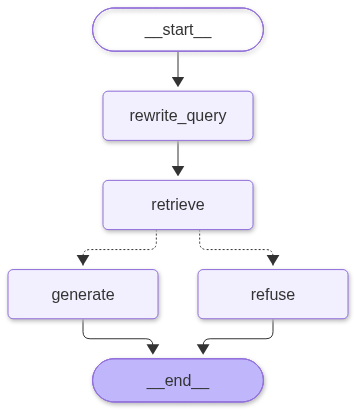

refusal threshold in use: 0.6885


In [11]:
from IPython.display import Image, display

assistant = Assistant(llm, vectorstore, settings)
graph = assistant.graph
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:  # the PNG renderer needs network access (mermaid.ink)
    print(f"(live PNG rendering unavailable: {type(exc).__name__}; showing docs/img/graph.png, rendered from this graph)")
    display(Image(str(PROJECT_ROOT / "docs" / "img" / "graph.png")))
    print(graph.get_graph().draw_mermaid())
print(f"refusal threshold in use: {assistant.threshold}")

### 6.1 · Tracing one question through the graph

`graph.stream(..., stream_mode="updates")` yields each node's state delta — the LangGraph tracing the brief recommends for debugging (LangSmith can be switched on with `LANGSMITH_TRACING=true`; this is the offline equivalent).

In [12]:
thread = assistant.new_thread()
for node, delta in assistant.stream_updates("¿Qué debe contener el manual del investigador (Investigator's Brochure)?", thread):
    summary = {k: (v[:80] + "…" if isinstance(v, str) and len(v) > 80 else v) for k, v in delta.items() if k not in ("messages", "sources", "context")}
    if "sources" in delta:
        summary["sources"] = [f"{s['short_cite']} §{s['section']}" for s in delta["sources"]]
    if "messages" in delta:
        summary["answer"] = delta["messages"][-1].content[:120] + "…"
    print(f"[{node}] {summary}")

[rewrite_query] (es) "¿Qué debe contener el manual del investigador (Investigator's Brochure)?" -> "What must the Investigator's Brochure contain?"


[retrieve] max_score=0.862 threshold=0.689 grounded=True chunks=6 passages=6 routed=-


[rewrite_query] {'question': "¿Qué debe contener el manual del investigador (Investigator's Brochure)?", 'standalone_question': "What must the Investigator's Brochure contain?", 'language': 'es'}
[retrieve] {'grounded': True, 'max_score': 0.8617952466011047, 'sources': ['ICH E6(R3) §A.1', 'ICH E6(R3) §3.15.1', 'ICH E6(R3) §A.3', 'ICH E2A §3', 'ICH E6(R3) §1.2.2', 'ICH E6(R3) §A.3.7']}


[generate] 879 chars, 6 sources


[generate] {'answer': 'El IB debe contener una compilación de datos clínicos y no clínicos sobre el IMP que sean relevantes para el estudio del…'}


## 7 · Conversation memory

`InMemorySaver` checkpoints the whole thread under a `thread_id`; the prompt only sees the last **10 messages** (5 turns), trimmed to start on a user turn. Three things to verify:

1. a follow-up that *refers* to the previous answer ("… about **that situation**?") is resolved by `rewrite_query` into a standalone question;
2. "summarise what you told me" works on turn 3 (message 5 of the window);
3. a **different thread** asking the same follow-up cold gets a different standalone question — threads are isolated.

In [13]:
thread_a = assistant.new_thread()
turns = [
    "What does ICH E6(R3) require when a participant is not capable of giving informed consent themselves?",
    "¿Dice lo mismo la Declaración de Helsinki sobre esa situación?",
    "Resume en dos puntos lo que me has dicho hasta ahora.",
]
for i, q in enumerate(turns, 1):
    a = assistant.ask(q, thread_a)
    print(f"\n──── turn {i} ─────────────────────────────────────────────")
    print("Q:", q)
    print("standalone question used for retrieval:", a.standalone_question)
    print("A:", a.text)
    print("sources:", "; ".join(f"[{s.n}] {s.citation}" for s in a.sources) or "(none)")
    time.sleep(2)

print(f"\nmessages persisted in thread A: {len(assistant.history(thread_a))} (window sends the last {settings.history_window})")

[rewrite_query] first turn, English: used as-is


[retrieve] max_score=0.784 threshold=0.689 grounded=True chunks=6 passages=6 routed=ich_e6_r3


[generate] 1203 chars, 6 sources



──── turn 1 ─────────────────────────────────────────────
Q: What does ICH E6(R3) require when a participant is not capable of giving informed consent themselves?
standalone question used for retrieval: What does ICH E6(R3) require when a participant is not capable of giving informed consent themselves?
A: When a trial includes participants who may only be enrolled with the consent of their legally acceptable representative, ICH E6(R3) requires that "the participants should be informed about the trial in a manner that facilitates their understanding and, if capable, the participant should sign and date the informed consent form or assent form as appropriate" [1].

Supporting details:
- When obtaining and documenting informed consent, the investigator must comply with applicable regulatory requirements, adhere to GCP, and follow ethical principles originating from the Declaration of Helsinki [3].
- The informed consent materials and process must be as clear and concise as possible, usi

[rewrite_query] (es) '¿Dice lo mismo la Declaración de Helsinki sobre esa situación?' -> 'Does the Declaration of Helsinki say the same thing about enrolling participants who are not capable of giving informed consent themselves?'


[retrieve] max_score=0.827 threshold=0.689 grounded=True chunks=6 passages=5 routed=wma_helsinki_2024


... (4 outputs left out)

[retrieve] max_score=0.781 threshold=0.689 grounded=True chunks=6 passages=5 routed=ich_e6_r3,wma_helsinki_2024


[generate] 794 chars, 5 sources



──── turn 3 ─────────────────────────────────────────────
Q: Resume en dos puntos lo que me has dicho hasta ahora.
standalone question used for retrieval: What are the key requirements from ICH E6(R3) and the Declaration of Helsinki regarding participants who are not capable of giving informed consent?
A: Esta respuesta proporciona información reglamentaria y no constituye asesoramiento legal o médico.

* ICH E6(R3) exige que, cuando los participantes no puedan dar el consentimiento por sí mismos, sus "legally acceptable representatives, acting in the participant s’ best interest , should provide consent prior to clinical trial participation", asegurando además que los participantes sean informados de manera que se facilite su comprensión [1].
* La Declaración de Helsinki (2024) coincide en la necesidad de recurrir al representante, añadiendo que estas personas "are in situations of particular vulnerability and are entitled to the corresponding safeguards", y que solo deben incluirse 


messages persisted in thread A: 6 (window sends the last 10)


In [14]:
thread_b = assistant.new_thread()
cold = assistant.ask("¿Dice lo mismo la Declaración de Helsinki sobre esa situación?", thread_b)
print("Same follow-up in a NEW thread (no history):")
print("standalone question:", cold.standalone_question)
print("A:", cold.text[:400], "…")
print(f"\nthread A has {len(assistant.history(thread_a))} messages, thread B has {len(assistant.history(thread_b))} — isolated.")

[rewrite_query] (es) '¿Dice lo mismo la Declaración de Helsinki sobre esa situación?' -> 'What does the Declaration of Helsinki say about that situation?'


[retrieve] max_score=0.826 threshold=0.689 grounded=True chunks=6 passages=6 routed=wma_helsinki_2024


[generate] 795 chars, 6 sources


Same follow-up in a NEW thread (no history):
standalone question: What does the Declaration of Helsinki say about that situation?
A: Esta es información regulatoria y no constituye asesoramiento legal o médico. 

Los fragmentos proporcionados no contienen la descripción de "esa situación" a la que se refiere en su pregunta, por lo que no es posible determinar si la Declaración de Helsinki dice lo mismo. 

Mi base de conocimiento cubre: ICH E6(R3) Good Clinical Practice, ICH E2A (definiciones y estándares para el reporte expedit …

thread A has 6 messages, thread B has 2 — isolated.


## 8 · Documented example conversations

Six questions chosen to exercise different behaviours: a definition, a timeline, a cross-document synthesis, a responsibilities question, an out-of-domain refusal and an in-domain-*looking* question about a document that is **not** in the knowledge base. For each: what was asked, the answer, the sources, and a note on whether it is right (judged against the guideline text).

> **Note (author):** the questions were drafted from the indexed guideline text with AI assistance, and I reviewed each one and its correctness note against the guideline — the ground truth for an expert assistant has to be checked by someone who can judge it. Edit `DEMO_QUESTIONS` to try others.

In [15]:
DEMO_QUESTIONS = [
    ("definition",      "What is the difference between a serious adverse event and a SUSAR?",
                        "E2A §II.B defines 'serious'; 'unexpected' (§II.C) depends on the reference safety information. A SUSAR is serious AND unexpected AND suspected to be related."),
    ("timeline",        "¿Cuántos días tiene el promotor para notificar una reacción adversa grave e inesperada que no sea mortal?",
                        "E2A §III.B.2: as soon as possible, no later than 15 calendar days after first knowledge."),
    ("multi-source",    "Compare what ICH E6(R3) and the Declaration of Helsinki require about informing participants of the risks of a trial.",
                        "Expect passages from both documents (E6(R3) 2.8.10 elements of consent; Helsinki ¶26) attributed separately."),
    ("responsibility",  "Under ICH E6(R3), what must the investigator do when a serious adverse event occurs?",
                        "E6(R3) 2.7 / 3.13: immediate reporting to the sponsor except those the protocol identifies as not needing immediate reporting; follow-up reports."),
    ("out-of-domain",   "¿Qué fármaco GLP-1 es mejor para perder peso?",
                        "Must refuse: clinical advice, not in the knowledge base. The refusal lists what the assistant does cover."),
    ("not-in-KB",       "What does 21 CFR Part 50 say about informed consent?",
                        "FDA regulation is not indexed. Expect either a refusal or an answer that stays within E6(R3)/Helsinki and says 21 CFR is not in its sources — never an invented citation."),
]

def behaved(kind, a):
    # A real check per behaviour type, not a label: the author's note below is the expert reading.
    docs = {s.doc_id for s in a.sources}
    low = a.text.lower()
    if kind == "out-of-domain":
        return not a.grounded
    if kind == "not-in-KB":
        return any(c in low for c in ("could not find", "not in my knowledge base", "does not contain"))
    if kind == "multi-source":
        return {"ich_e6_r3", "wma_helsinki_2024"} <= docs and a.grounded
    if kind == "timeline":
        return a.grounded and "15" in a.text and "ich_e2a" in docs
    return a.grounded and bool(a.sources)


for i, (kind, q, note) in enumerate(DEMO_QUESTIONS, 1):
    a = assistant.ask(q)      # fresh thread each time
    print(f"\n{'═'*100}\n{i}. [{kind}]  {q}\n{'─'*100}")
    print(a.text)
    print(f"\n   grounded={a.grounded}  max_score={a.max_score:.3f}  sources: " + ("; ".join(f"[{s.n}] {s.citation}" for s in a.sources) or "(none)"))
    ok = behaved(kind, a)
    print(f"   {'✔' if ok else '✘'} behaviour check: {kind} — {'as expected' if ok else 'NOT as expected'}")
    print(f"   author's note: {note}")
    time.sleep(2)

[rewrite_query] first turn, English: used as-is


[retrieve] max_score=0.820 threshold=0.689 grounded=True chunks=6 passages=5 routed=-


[generate] 1829 chars, 5 sources



════════════════════════════════════════════════════════════════════════════════════════════════════
1. [definition]  What is the difference between a serious adverse event and a SUSAR?
────────────────────────────────────────────────────────────────────────────────────────────────────
A Serious Adverse Event (SAE) is any untoward medical occurrence that results in death, is life-threatening, requires inpatient hospitalization or prolongation of existing hospitalization, results in persistent or significant disability/incapacity, or is a congenital anomaly/birth defect, without necessarily having a causal relationship to the treatment [1, 2]. In contrast, a SUSAR (Suspected Unexpected Serious Adverse Reaction) is an adverse reaction that meets three specific criteria: it is serious, unexpected, and there is a reasonable possibility that the drug caused the adverse drug reaction [1].

Supporting details:
* **SAE Definition:** "Any unfavourable medical occurrence that is considered seri

[rewrite_query] (es) '¿Cuántos días tiene el promotor para notificar una reacción adversa grave e inesperada que no sea mortal?' -> 'What is the timeframe for the sponsor to report a serious and unexpected adverse reaction that is not fatal?'


[retrieve] max_score=0.853 threshold=0.689 grounded=True chunks=6 passages=5 routed=-


... (14 outputs left out)

[rewrite_query] first turn, English: used as-is


[retrieve] max_score=0.770 threshold=0.689 grounded=True chunks=6 passages=5 routed=-


[generate] 184 chars, 5 sources



════════════════════════════════════════════════════════════════════════════════════════════════════
6. [not-in-KB]  What does 21 CFR Part 50 say about informed consent?
────────────────────────────────────────────────────────────────────────────────────────────────────
I could not find information about 21 CFR Part 50 in my knowledge base. My knowledge base covers ICH E6(R3) Good Clinical Practice, ICH E2A, and the WMA Declaration of Helsinki (2024).

   grounded=True  max_score=0.770  sources: [1] ICH E6(R3) §2, p.10; [2] ICH E6(R3) §2.8.7, p.24; [3] ICH E6(R3) §2.8.10, pp.24–26; [4] Declaration of Helsinki (2024) ¶28; [5] ICH E6(R3) §2.8.5, p.23
   ✔ behaviour check: not-in-KB — as expected
   author's note: FDA regulation is not indexed. Expect either a refusal or an answer that stays within E6(R3)/Helsinki and says 21 CFR is not in its sources — never an invented citation.


## 9 · Evaluation on the golden set

`data/eval/golden.jsonl` holds 25 questions drafted from the indexed text (with AI assistance) and reviewed by the author, each in **English and Spanish** (50 runs): 19 in-domain with the document and section that answers them (two need two documents), 4 out-of-domain that must be refused, and 2 that *look* in-domain but ask about documents deliberately not indexed (21 CFR Part 50, EU CTR 536/2014). Every reference is checked against the indexed text by `tests/test_golden_consistency.py`.

Two layers of metrics:

* **Retrieval** (below, live — the query vectors are cached, so this costs nothing): did the top-6 contain the expected document and section, did out-of-domain questions fall under the gate, did in-domain ones stay above it.
* **Answers** (`scripts/03_evaluate.py --with-answers`, ~60 LLM calls, results committed in `docs/`): keyword coverage of the generated answers (accepting the Spanish rendering a Spanish answer uses) and honesty on not-indexed documents. The first full run of v3 exposed truncated lists, a refused multi-step question and an English refusal to a Spanish question; prompt v4, context expansion and document routing were the response. The comparison uses identical keywords for both runs.

In [16]:
from IPython.display import Markdown
from compliance_assistant.evaluation import evaluate_retrieval, load_golden

golden = load_golden(settings.golden_path)
report = evaluate_retrieval(vectorstore, golden, settings, assistant.threshold)
m = report.metrics()
print(f"{len(golden)} items x 2 languages = {len(report.results)} retrieval runs")
for key in ("doc_hit_rate@6_en", "doc_hit_rate@6_es", "section_hit_rate@6_en", "section_hit_rate@6_es",
            "refusal_accuracy_en", "refusal_accuracy_es", "false_refusal_rate_en", "false_refusal_rate_es"):
    print(f"  {key:<24} {m[key]}")
misses = [r for r in report.results if r.doc_hit is False or r.section_hit is False]
print("misses:", [(r.id, r.language) for r in misses] or "none")

25 items x 2 languages = 50 retrieval runs
  doc_hit_rate@6_en        1.0
  doc_hit_rate@6_es        1.0
  section_hit_rate@6_en    0.947
  section_hit_rate@6_es    0.947
  refusal_accuracy_en      1.0
  refusal_accuracy_es      1.0
  false_refusal_rate_en    0.0
  false_refusal_rate_es    0.0
misses: [('multi_consent_capacity', 'en'), ('multi_consent_capacity', 'es')]


In [17]:
import re

def metric_table(path):
    rows = re.findall(r"^\| ([a-z_@0-9]+) \| ([^|]+) \|$", (PROJECT_ROOT / path).read_text(encoding="utf-8"), flags=re.M)
    return {k: v.strip() for k, v in rows if k != "metric"}   # skip the table's header row

before, after = metric_table("docs/evaluation_baseline_v3.md"), metric_table("docs/evaluation.md")
lines = ["| metric | v3 baseline | v4 + expansion + routing |", "|---|---|---|"]
lines += [f"| {k} | {before.get(k, 'n/a')} | {after.get(k, 'n/a')} |" for k in after]
display(Markdown("\n".join(lines)))

| metric | v3 baseline | v4 + expansion + routing |
|---|---|---|
| doc_hit_rate@6_en | 1.0 | 1.0 |
| section_hit_rate@6_en | 0.947 | 0.947 |
| false_refusal_rate_en | 0.0 | 0.0 |
| refusal_accuracy_en | 1.0 | 1.0 |
| doc_hit_rate@6_es | 1.0 | 1.0 |
| section_hit_rate@6_es | 1.0 | 0.947 |
| false_refusal_rate_es | 0.0 | 0.0 |
| refusal_accuracy_es | 1.0 | 1.0 |
| keyword_coverage | 0.815 | 0.974 |
| not_in_kb_honesty | 1.0 | 1.0 |

### 9.1 · Do the improvements generalise? Held-out set and LLM judge

Two checks against over-fitting to the golden set:

* **Held-out set** (`data/eval/heldout.jsonl`, 12 items × EN/ES) written *after* v4 was frozen, on topics the golden set does not touch, run once per configuration and never tuned on.
* **LLM judge** (`scripts/05_judge.py`) compares every in-domain answer with the expert reference: correct = 1, partially correct = 0.5, incorrect = 0 — correctness, which keyword coverage only approximates. The intended judge, `gemini-3.5-flash` (larger than the answering model), allows 20 requests a day on the free tier, enough for one answer set; all four sets were therefore judged with `gemini-3.5-flash-lite`, and the two judges are compared on the 38 answers `flash` did judge.

Both were produced by the scripts; the cell below only reads the committed results.

In [18]:
import statistics

def judge_mean(path):
    p = PROJECT_ROOT / path
    if not p.exists():
        return "not run"
    rows = [json.loads(l) for l in p.read_text(encoding="utf-8").splitlines() if l.strip()]
    counts = {v: sum(r["verdict"] == v for r in rows) for v in ("correct", "partially_correct", "incorrect")}
    return f"{statistics.mean(r['score'] for r in rows):.2f} ({counts['correct']}/{counts['partially_correct']}/{counts['incorrect']})"

ho_before, ho_after = metric_table("docs/heldout_baseline_v3.md"), metric_table("docs/heldout_evaluation.md")
J = "judge-gemini-3.5-flash-lite"   # the judge that covers all four answer sets (see below)
rows = [
    "| | v3 baseline | v4 + expansion + routing |", "|---|---|---|",
    f"| Judge score, golden set (correct/partial/incorrect) | {judge_mean(f'data/eval/answers_baseline_v3.{J}.jsonl')} | {judge_mean(f'data/eval/answers.{J}.jsonl')} |",
    f"| Judge score, held-out set | {judge_mean(f'data/eval/heldout_answers_baseline_v3.{J}.jsonl')} | {judge_mean(f'data/eval/heldout_answers.{J}.jsonl')} |",
]
for k in ("keyword_coverage", "doc_hit_rate@6_en", "doc_hit_rate@6_es", "section_hit_rate@6_en", "section_hit_rate@6_es",
          "refusal_accuracy_en", "refusal_accuracy_es", "false_refusal_rate_en", "false_refusal_rate_es", "not_in_kb_honesty"):
    rows.append(f"| Held-out {k} | {ho_before.get(k, 'n/a')} | {ho_after.get(k, 'n/a')} |")
display(Markdown("\n".join(rows)))

# Is the cheaper judge trustworthy? Compare it with gemini-3.5-flash on the 38 golden v3 answers both judged.
from compliance_assistant.judge import agreement
def load(path):
    p = PROJECT_ROOT / path
    return [json.loads(l) for l in p.read_text(encoding="utf-8").splitlines() if l.strip()] if p.exists() else []
stats = agreement(load("data/eval/answers_baseline_v3.judge-gemini-3.5-flash.jsonl"),
                  load(f"data/eval/answers_baseline_v3.{J}.jsonl"))
print("judge agreement, gemini-3.5-flash (a) vs gemini-3.5-flash-lite (b):", json.dumps(stats, indent=1))

| | v3 baseline | v4 + expansion + routing |
|---|---|---|
| Judge score, golden set (correct/partial/incorrect) | 0.78 (23/13/2) | 0.95 (35/2/1) |
| Judge score, held-out set | 0.95 (18/2/0) | 1.00 (20/0/0) |
| Held-out keyword_coverage | 0.925 | 1.0 |
| Held-out doc_hit_rate@6_en | 1.0 | 1.0 |
| Held-out doc_hit_rate@6_es | 1.0 | 1.0 |
| Held-out section_hit_rate@6_en | 1.0 | 1.0 |
| Held-out section_hit_rate@6_es | 1.0 | 1.0 |
| Held-out refusal_accuracy_en | 1.0 | 1.0 |
| Held-out refusal_accuracy_es | 1.0 | 1.0 |
| Held-out false_refusal_rate_en | 0.0 | 0.0 |
| Held-out false_refusal_rate_es | 0.0 | 0.0 |
| Held-out not_in_kb_honesty | 1.0 | 1.0 |

judge agreement, gemini-3.5-flash (a) vs gemini-3.5-flash-lite (b):

 {
 "n": 38,
 "exact_agreement": 0.789,
 "mean_abs_score_diff": 0.105,
 "mean_score_a": 0.697,
 "mean_score_b": 0.776,
 "confusion": {
  "correct -> correct": 16,
  "correct -> partially_correct": 1,
  "incorrect -> incorrect": 2,
  "partially_correct -> correct": 7,
  "partially_correct -> partially_correct": 12
 }
}


## 10 · Interactive chat

Run the cells below and talk to the agent: type a question (English or Spanish) and press *Ask*; *New thread* starts a fresh conversation. Every turn goes through the same `chat()` function, which prints the answer immediately with its sources.

When the notebook is executed headlessly (`NB_INTERACTIVE=0`, as for the committed outputs) there is nobody to type, so the cell instead sends a short two-turn conversation through that same function — what you see below is a real exchange, not a recording. Without widgets (some Colab/VS Code setups), call `chat_loop()` for a plain text prompt.

In [19]:
def chat(question: str, thread_id: str) -> None:
    # One conversational turn: ask the agent, print the answer and its sources.
    a = assistant.ask(question, thread_id)
    print(f"\nyou> {question}")
    print(f"assistant> {a.text}")
    print("   sources: " + ("; ".join(f"[{s.n}] {s.citation}" for s in a.sources) or "(none — refused)"))


def chat_loop() -> None:
    # Plain-text chat for environments without widgets; an empty line or /quit ends it.
    t = assistant.new_thread()
    while (q := input("you> ").strip()) and q != "/quit":
        chat(q, t)


INTERACTIVE = os.environ.get("NB_INTERACTIVE", "1") == "1"
chat_thread = {"id": assistant.new_thread()}

if INTERACTIVE:
    import ipywidgets as w
    box = w.Text(placeholder="Ask about GCP, safety reporting or Helsinki… (EN/ES)", layout=w.Layout(width="80%"))
    ask_btn, new_btn = w.Button(description="Ask", button_style="primary"), w.Button(description="New thread")
    out = w.Output()

    def on_ask(_=None):
        q = box.value.strip()
        if q:
            box.value = ""
            with out:
                chat(q, chat_thread["id"])

    def on_new(_=None):
        chat_thread["id"] = assistant.new_thread()
        with out:
            print("\n(new conversation)")

    ask_btn.on_click(on_ask); new_btn.on_click(on_new); box.on_submit(on_ask)
    display(w.VBox([w.HBox([box, ask_btn, new_btn]), out]))
else:
    print("Headless run: a real two-turn conversation through chat(), the function the widget calls.")
    chat("Who must keep the essential records of a clinical trial, and for how long?", chat_thread["id"])
    chat("¿Y quién puede pedir acceso a esos documentos?", chat_thread["id"])

[rewrite_query] first turn, English: used as-is


[retrieve] max_score=0.852 threshold=0.689 grounded=True chunks=6 passages=6 routed=-


Headless run: a real two-turn conversation through chat(), the function the widget calls.


[generate] 1042 chars, 6 sources



you> Who must keep the essential records of a clinical trial, and for how long?
assistant> The sponsor and the investigator/institution (and where applicable, service providers) must retain essential records securely for the period required by applicable regulatory requirements [1, 2, 3, 4]. 

Essential records should be retained according to the following standards:
* **Responsible party:** "The original records should generally be retained by the responsible party who generated them." [2]
* **Sponsor responsibilities:** The sponsor (or subsequent owners of the data) must retain sponsor-specific essential records pertaining to the trial [4]. The sponsor should also obtain agreements from the investigator/institution and, where applicable, service providers to retain essential records for the required retention period [1].
* **Duration:** Essential records must be retained for the required period in accordance with applicable regulatory requirements [1, 3, 4], or until the sponsor inf

[rewrite_query] (es) '¿Y quién puede pedir acceso a esos documentos?' -> 'Who can request access to essential records of a clinical trial?'


[retrieve] max_score=0.845 threshold=0.689 grounded=True chunks=6 passages=4 routed=-


[generate] 1258 chars, 4 sources



you> ¿Y quién puede pedir acceso a esos documentos?
assistant> Los registros esenciales de un ensayo clínico pueden ser solicitados por autoridades regulatorias, monitores, auditores y comités institucionales de revisión/comités éticos independientes (IRB/IEC, según corresponda) [1].

Los siguientes detalles especifican quiénes pueden pedir acceso y cómo:
* **Autoridades regulatorias, monitores, auditores e IRB/IECs:** "These essential records should be available to regulatory authorities, monitors, auditors and IRB s/IECs (as appropriate) upon request to enable appropriate evaluation of the trial conduct in order to ensure the reliability of trial results." [1]
* **Acceso directo a los registros:** "Upon request of the monitor, auditor, IRB/IEC or regulatory authority, the investigator/institution should make available for direct access all requested trial -related records." [3]
* **Inspecciones y auditorías:** Las autoridades regulatorias y la función de auditoría independiente del 

## 11 · Limitations and next steps

**Limitations**
- *Three documents.* Enough for GCP, expedited safety reporting and research ethics; questions about EU CTR 536/2014, GVP modules or FDA regulations are refused or answered only from what E6(R3) says.
- *PDF extraction.* ICH tables (essential records, E6(R3) Appendix C) flatten into prose; the cleaner removes running headers and TOC lines but cannot restore table structure.
- *Multi-hop questions.* "From the investigator to the regulator, who reports to whom and when?" needs E6(R3) §2.7.2, §3.13.2 and E2A together; one retrieval pass does not bring every hop, so the answer can miss a step (the only *incorrect* judge verdict of the v4 run, in Spanish — section 9.1).
- *Document routing has a cost.* On the E6(R3)-vs-Helsinki comparison the E6(R3)-filtered slots pick §2.8.1 and the glossary rather than Principle 2.1 (the two section misses in section 9), although the generated answers still quote it.
- *Threshold is corpus-specific.* The calibrated refusal gate (0.69) was read off six in-domain and six out-of-domain queries, one of which (the GLP-1 question) also appears in the golden set and the demo; it must be recalibrated when the corpus or the embedding model changes. Borderline in-domain questions phrased very differently from the text can be refused.
- *Memory is per process.* `InMemorySaver` lives in RAM; the Streamlit app gives each browser session its own `thread_id`, but a restart forgets everything. A `SqliteSaver` would persist threads.
- *Judge.* The judge is the answering model; the larger `gemini-3.5-flash` agreed with it on 78.9 % of 38 answers and was stricter, so absolute scores read optimistic (section 9.1).
- *Free tier.* Embedding the corpus costs ~17 requests; each chat turn costs 1–2 LLM calls. The build is resumable and cached so the quota is never spent twice.

**Next steps (in order of value)**
1. Query decomposition: one retrieval per step of a multi-hop question.
2. Add EMA GVP Module VI and EU CTR 536/2014 (the ingestion is per-document and idempotent; recalibrate the gate and extend the golden set).
3. A faithfulness judge (answer vs. retrieved passages) — the current judge measures correctness against expert references.
4. Hybrid retrieval (BM25 + vectors) for exact section numbers and acronyms.
5. A `guard_input` node (prompt-injection and PII screening) before `rewrite_query`, and a persistent checkpointer.